# Estrategias comerciales con datos

El objetivo de este proyecto es estimar la cantidad de personas que tuvieron la oportunidad de ver la pantalla en cada hora del día. A esto lo llamamos audiencia potencial, es decir, personas que pasaron por la zona y podrían haber visto el anuncio. No indica cuántas personas efectivamente miraron la pantalla ni cuantas recordaron el anuncio.

Se detectan seis clases de objetos con un modelo pre entrenado: personas, camiones, buses, motos y bicicletas, que estén en circulación por la zona. La cámara ve a los peatones y a quienes van en moto o bicicleta. No ve a quienes viajan dentro de autos y buses, a esas personas las estimamos con un supuesto de ocupantes por vehículo.

Contamos objetos que pasan, no objetos que se ven. El video es una sucesión de imágenes. Una persona que tarda en cruzar aparece en varias imágenes; si contáramos lo que se ve en cada imagen, la contaríamos más de una vez. Por esto seguimos a cada objeto de una imagen a la siguiente y le asignamos un número de identificación, para contarlo una sola vez.

Un objeto (persona, auto, bus, camión, moto o bicicleta) se cuenta si el sistema lo sigue durante al menos 1 segundo. Los registros de menos de 1 segundo suelen ser errores: pedazos de un objeto que el sistema perdió de vista y volvió a encontrar, o falsas detecciones. Las personas que esperan el bus también se cuentan, porque están expuestas a la pantalla. Esta regla no distingue a los vehículos estacionados de los que circulan, por lo que estos también se cuentan; lo analizamos como una limitación.

## Procesar los 24 clips con TrackTrack ##


**Qué deja en la carpeta `resultados`:**

| Archivo | Contenido |
|---|---|
| `tracks/<clip>.csv` | Una fila por objeto seguido y por cuadro: cuadro, segundo, ID, clase, confianza y posición de la caja (`x1, y1, x2, y2`) |
| `conteo_crudo.csv` | Una fila por hora: IDs distintos por clase (el paso 6 del notebook base), % de IDs que duran menos de 1 segundo y minutos de proceso |
| `videos/<clip>_seguimiento.mp4` | El video con cajas e IDs, solo para las horas de `HORAS_CON_VIDEO` |
| `parametros.json` | Modelo, tracker, umbrales y versiones usadas |


El notebook tiene que estar en la misma carpeta que `sample`. Las rutas son relativas, así que
funciona en cualquier computadora con esa organización.

##  Configuración

Todos los parámetros que influyen en el conteo están en esta celda. Son los mismos que en el notebook
base, salvo el tracker: se usa **TrackTrack**, que en la comparación de trackers sobre el clip de las
13:30 fue el que menos fragmentó los IDs.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `MODELO` | `yolo26s.pt` | El detector (YOLO26 *small*, entrenado en COCO) |
| `IMGSZ` | 1280 | Tamaño al que se procesa cada cuadro |
| `CONF` | 0.25 | Confianza mínima para aceptar una detección |
| `TRACKER` | `tracktrack.yaml` | El algoritmo que asigna y mantiene los IDs entre cuadros |

In [1]:
!pip install -q ultralytics

In [2]:
import hashlib
import json
import shutil
import subprocess
import time
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import display
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
# --- Parámetros del conteo ---
MODELO = "yolo26s.pt"
IMGSZ = 1280
CONF = 0.25
TRACKER = "tracktrack.yaml"

# Las clases de COCO que importan para el proyecto, con su número de clase (igual que el notebook base).
CLASES = {0: "persona", 1: "bicicleta", 2: "auto", 3: "moto", 5: "bus", 7: "camión"}
ORDEN_CLASES = ["persona", "auto", "bus", "camión", "moto", "bicicleta"]

# En una Mac con Apple Silicon la GPU se pide explícitamente ("mps"); con None, Ultralytics usa la
# GPU NVIDIA si la hay y si no, la CPU.
DEVICE = "mps" if torch.backends.mps.is_available() else None

# --- Rutas (relativas a la carpeta del notebook) ---
CARPETA_VIDEOS = Path("sample")
MANIFIESTO = CARPETA_VIDEOS / "manifiesto.csv"
CARPETA_RESULTADOS = Path("resultados")
CARPETA_PRUEBA = Path("resultados_prueba")

# Horas para las que además se graba el video con cajas e IDs.
HORAS_CON_VIDEO = {"00:30", "13:30", "18:30"}

# --- Manifiesto: qué clip corresponde a cada hora y su SHA-256 ---
manifiesto = pd.read_csv(MANIFIESTO, dtype={"hora": str}).set_index("hora")
print(f"Manifiesto: {len(manifiesto)} clips, de {manifiesto.index.min()} a {manifiesto.index.max()}")
print(f"Ultralytics {ultralytics.__version__} · PyTorch {torch.__version__} · "
      f"dispositivo: {'GPU' if torch.cuda.is_available() else DEVICE or 'CPU'}")

Manifiesto: 24 clips, de 00:30 a 23:30
Ultralytics 8.4.210 · PyTorch 2.15.0+cpu · dispositivo: CPU




`procesar_hora(hora)`:

1. **Abre el clip** de esa hora desde `sample` y comprueba que su SHA-256 coincida con el del
   manifiesto.
2. **Sigue los objetos** con TrackTrack en todos los cuadros. A diferencia del notebook base, guarda
   también la **confianza y la posición de cada caja**. El modelo se carga de nuevo en cada hora para que el seguimiento
   empiece de cero.
3. **Graba el video** con cajas e IDs, solo si la hora está en `HORAS_CON_VIDEO`.
4. **Cuenta los IDs distintos** por clase, asignando a cada ID la clase que más veces tuvo, y calcula
   qué porcentaje de los IDs dura menos de 1 segundo.
5. **Guarda** el CSV del seguimiento y actualiza la fila de esa hora en `conteo_crudo.csv`.

El CSV se escribe primero con otro nombre y se renombra al terminar: si el proceso se corta a mitad
de un clip, no queda un archivo incompleto que parezca terminado.

La última columna de la tabla que muestra cada hora es la **referencia del manifiesto**, solo para
tener una idea del orden de magnitud. No es un conteo verdadero: el conteo crudo todavía incluye
autos estacionados, gente esperando el bus e IDs fragmentados.

In [ ]:
def clip_de(hora):
    # Devuelve la ruta del clip de esa hora y comprueba su SHA-256 contra el manifiesto.
    if hora not in manifiesto.index:
        raise ValueError(f"La hora {hora!r} no está en el manifiesto. Usar el formato '13:30'.")
    fila = manifiesto.loc[hora]
    video = CARPETA_VIDEOS / fila["clip"]
    if not video.exists():
        raise FileNotFoundError(f"No encuentro el clip {video.resolve()}")
    if hashlib.sha256(video.read_bytes()).hexdigest() != fila["sha256"]:
        raise ValueError(f"El SHA-256 de {video.name} no coincide con el manifiesto: el archivo está dañado o es otro.")
    return video


def seguir_objetos(video, archivo_video=None):
    # Paso 5 del notebook base: seguimiento en todos los cuadros. Devuelve una fila por objeto y cuadro.
    modelo = YOLO(MODELO)  # se carga de nuevo para que el seguimiento empiece de cero
    captura = cv2.VideoCapture(str(video))
    fps = captura.get(cv2.CAP_PROP_FPS)
    total = int(captura.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH)), int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))
    captura.release()

    escritor = None
    if archivo_video is not None:
        archivo_video.parent.mkdir(parents=True, exist_ok=True)
        escritor = cv2.VideoWriter(str(archivo_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
        if not escritor.isOpened():
            raise RuntimeError(f"No se pudo crear el video de seguimiento: {archivo_video}")

    filas = []
    try:
        for cuadro_n, r in enumerate(modelo.track(str(video), stream=True, tracker=TRACKER, imgsz=IMGSZ,
                                                  conf=CONF, classes=list(CLASES), device=DEVICE,
                                                  verbose=False)):
            if escritor is not None:
                escritor.write(r.plot(conf=False, font_size=12, line_width=2, color_mode="instance"))
            if cuadro_n % 300 == 0:
                print(f"   cuadro {cuadro_n:>5,} de {total:,}", flush=True)
            if r.boxes.id is None:
                continue
            ids = r.boxes.id.int().tolist()
            clases = r.boxes.cls.int().tolist()
            confianzas = r.boxes.conf.cpu().numpy().astype(float).round(3).tolist()
            cajas = r.boxes.xyxy.cpu().numpy().astype(float).round(1).tolist()
            for id_, c, cf, (x1, y1, x2, y2) in zip(ids, clases, confianzas, cajas):
                filas.append({"cuadro": cuadro_n, "segundo": round(cuadro_n / fps, 3), "id": id_,
                              "clase": CLASES[c], "conf": cf, "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    finally:
        if escritor is not None:
            escritor.release()

    columnas = ["cuadro", "segundo", "id", "clase", "conf", "x1", "y1", "x2", "y2"]
    return pd.DataFrame(filas, columns=columnas), fps


def convertir_a_h264(archivo_video):
    # El navegador y el reproductor de Windows suelen no abrir MP4V; con ffmpeg se pasa a H.264.
    # Sin ffmpeg queda en MP4V, que VLC reproduce sin problema.
    ffmpeg = shutil.which("ffmpeg")
    if not ffmpeg:
        return "MP4V (sin ffmpeg; abrirlo con VLC)"
    temporal = archivo_video.with_name(archivo_video.stem + "_h264.mp4")
    conversion = subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(archivo_video),
                                 "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart",
                                 str(temporal)], capture_output=True, text=True)
    if conversion.returncode != 0:
        return "MP4V (falló la conversión con ffmpeg)"
    temporal.replace(archivo_video)
    return "H.264"


def contar_ids(seguimiento, fps):
    # Paso 6 del notebook base: IDs distintos por clase (cada ID con su clase más frecuente).
    clase_de_cada_id = seguimiento.groupby("id").clase.agg(lambda s: s.mode().iloc[0])
    cuenta = clase_de_cada_id.value_counts().reindex(ORDEN_CLASES, fill_value=0)
    duracion = seguimiento.groupby("id").cuadro.agg(lambda s: (s.max() - s.min() + 1) / fps)
    return cuenta, duracion


def actualizar_conteo_crudo(carpeta, fila):
    # Reemplaza (o agrega) la fila de esa hora en conteo_crudo.csv, ordenado por hora.
    archivo = carpeta / "conteo_crudo.csv"
    tabla = pd.read_csv(archivo, dtype={"hora": str}, encoding="utf-8-sig") if archivo.exists() else pd.DataFrame()
    anterior = tabla[tabla.hora == fila["hora"]] if len(tabla) else tabla
    if pd.isna(fila["minutos_proceso"]) and len(anterior):
        fila["minutos_proceso"] = anterior.minutos_proceso.iloc[0]  # se conserva el tiempo de la corrida original
    if len(tabla):
        tabla = tabla[tabla.hora != fila["hora"]]
    tabla = pd.concat([tabla, pd.DataFrame([fila])], ignore_index=True).sort_values("hora")
    tabla.to_csv(archivo, index=False, encoding="utf-8-sig")


def guardar_parametros(carpeta):
    parametros = {"modelo": MODELO, "imgsz": IMGSZ, "conf": CONF, "tracker": TRACKER,
                  "clases": CLASES, "horas_con_video": sorted(HORAS_CON_VIDEO),
                  "ultralytics": ultralytics.__version__, "torch": torch.__version__,
                  "ultima_ejecucion": datetime.now().isoformat(timespec="seconds")}
    (carpeta / "parametros.json").write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8")


def procesar_hora(hora, carpeta=CARPETA_RESULTADOS, guardar_video=None, rehacer=False):
    # Procesa el clip de una hora y guarda sus resultados en `carpeta`.
    video = clip_de(hora)
    carpeta_tracks = carpeta / "tracks"
    carpeta_tracks.mkdir(parents=True, exist_ok=True)
    archivo_tracks = carpeta_tracks / f"{video.stem}.csv"
    if guardar_video is None:
        guardar_video = hora in HORAS_CON_VIDEO
    guardar_parametros(carpeta)

    if archivo_tracks.exists() and not rehacer:
        print(f"{hora}: ya estaba procesada, leo {archivo_tracks}")
        seguimiento = pd.read_csv(archivo_tracks, encoding="utf-8-sig")
        fps = cv2.VideoCapture(str(video)).get(cv2.CAP_PROP_FPS)
        minutos = float("nan")
    else:
        print(f"{hora}: procesando {video.name} ({'con' if guardar_video else 'sin'} video)", flush=True)
        archivo_video = carpeta / "videos" / f"{video.stem}_seguimiento.mp4" if guardar_video else None
        inicio = time.time()
        seguimiento, fps = seguir_objetos(video, archivo_video)
        temporal = archivo_tracks.with_suffix(".tmp")
        seguimiento.to_csv(temporal, index=False, encoding="utf-8-sig")
        temporal.replace(archivo_tracks)
        if archivo_video is not None:
            formato = convertir_a_h264(archivo_video)
            print(f"   video: {archivo_video} · {formato}")
        minutos = (time.time() - inicio) / 60
        print(f"   listo en {minutos:.1f} min · {len(seguimiento):,} detecciones con ID · {archivo_tracks}")

    if seguimiento.empty:
        print("   ATENCIÓN: no hubo ninguna detección con ID en este clip.")
        cuenta = pd.Series(0, index=ORDEN_CLASES)
        duracion = pd.Series(dtype=float)
    else:
        cuenta, duracion = contar_ids(seguimiento, fps)

    fila = {"hora": hora, "clip": video.name,
            **{f"ids_{c}": int(cuenta[c]) for c in ORDEN_CLASES},
            "ids_total": int(cuenta.sum()),
            "pct_ids_menos_1s": round(float((duracion < 1).mean() * 100), 1) if len(duracion) else 0.0,
            "detecciones_con_id": len(seguimiento),
            "minutos_proceso": round(minutos, 2) if minutos == minutos else float("nan")}
    actualizar_conteo_crudo(carpeta, fila)

    referencia = manifiesto.loc[hora, [f"ref_{c}" for c in ["personas", "autos", "buses", "camiones", "motos", "bicicletas"]]]
    vista = pd.DataFrame({"IDs distintos (crudo)": cuenta.values,
                          "referencia del manifiesto": referencia.astype(int).values}, index=ORDEN_CLASES)
    print(f"   {fila['pct_ids_menos_1s']:.0f} % de los IDs duran menos de 1 segundo")
    display(vista)
    return fila

## Procesamiento por hora

Una sección por clip. Cada celda procesa su hora, guarda el CSV del seguimiento en `resultados/tracks`
y actualiza su fila en `resultados/conteo_crudo.csv`. Las horas 00:30, 13:30 y 18:30 graban además el
video con cajas en `resultados/videos`.

Las secciones son independientes: se pueden correr en cualquier orden, en varias sesiones o repartidas
entre computadoras (copiando después los CSV a la misma carpeta `resultados/tracks`).

### Hora 00:30 · con video

In [ ]:
r_0030 = procesar_hora("00:30")

00:30: procesando 2st01_20261023_003000.mp4 (con video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   video: resultados\videos\2st01_20261023_003000_seguimiento.mp4 · MP4V (sin ffmpeg; abrirlo con VLC)
   listo en 11.8 min · 13,709 detecciones con ID · resultados\tracks\2st01_20261023_003000.csv
   4 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,32,29
auto,11,10
bus,4,4
camión,0,0
moto,1,3
bicicleta,0,0


### Hora 01:30

In [ ]:
r_0130 = procesar_hora("01:30")

01:30: procesando 2st01_20261023_013000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 11.4 min · 11,467 detecciones con ID · resultados\tracks\2st01_20261023_013000.csv
   7 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,17,13
auto,10,8
bus,0,0
camión,0,0
moto,0,1
bicicleta,0,1


### Hora 02:30

In [ ]:
r_0230 = procesar_hora("02:30")

02:30: procesando 2st01_20261023_023000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 12.6 min · 5,601 detecciones con ID · resultados\tracks\2st01_20261023_023000.csv
   0 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,8,9
auto,2,0
bus,0,0
camión,0,0
moto,0,0
bicicleta,0,0


### Hora 03:30

In [ ]:
r_0330 = procesar_hora("03:30")

03:30: procesando 2st01_20261023_033000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 11.8 min · 10,765 detecciones con ID · resultados\tracks\2st01_20261023_033000.csv
   13 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,13,16
auto,10,6
bus,0,0
camión,0,0
moto,0,0
bicicleta,0,0


### Hora 04:30

In [ ]:
r_0430 = procesar_hora("04:30")

04:30: procesando 2st01_20261023_043000.mp4 (sin video)
   cuadro     0 de 1,801
   cuadro   300 de 1,801
   cuadro   600 de 1,801
   cuadro   900 de 1,801
   cuadro 1,200 de 1,801
   cuadro 1,500 de 1,801
   cuadro 1,800 de 1,801
   listo en 10.4 min · 7,677 detecciones con ID · resultados\tracks\2st01_20261023_043000.csv
   33 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,1,1
auto,7,3
bus,1,1
camión,0,0
moto,0,2
bicicleta,0,0


### Hora 05:30

In [ ]:
r_0530 = procesar_hora("05:30")

05:30: procesando 2st01_20261023_053000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.3 min · 3,548 detecciones con ID · resultados\tracks\2st01_20261023_053000.csv
   0 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,1,3
auto,6,4
bus,1,1
camión,0,0
moto,0,0
bicicleta,0,1


### Hora 06:30

In [ ]:
r_0630 = procesar_hora("06:30")

06:30: procesando 2st01_20261023_063000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 10.4 min · 7,267 detecciones con ID · resultados\tracks\2st01_20261023_063000.csv
   19 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,18,18
auto,7,6
bus,0,0
camión,0,0
moto,1,1
bicicleta,0,0


### Hora 07:30

In [ ]:
r_0730 = procesar_hora("07:30")

07:30: procesando 2st01_20261023_073000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 9.9 min · 24,891 detecciones con ID · resultados\tracks\2st01_20261023_073000.csv
   9 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,32,29
auto,49,35
bus,5,4
camión,0,0
moto,1,2
bicicleta,1,1


### Hora 08:30

In [ ]:
r_0830 = procesar_hora("08:30")

08:30: procesando 2st01_20261023_083000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.4 min · 23,301 detecciones con ID · resultados\tracks\2st01_20261023_083000.csv
   7 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,22,32
auto,50,41
bus,0,0
camión,3,5
moto,0,1
bicicleta,1,1


### Hora 09:30

In [ ]:
r_0930 = procesar_hora("09:30")

09:30: procesando 2st01_20261023_093000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 10.6 min · 27,926 detecciones con ID · resultados\tracks\2st01_20261023_093000.csv
   10 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,48,42
auto,66,35
bus,12,9
camión,4,3
moto,1,2
bicicleta,2,3


### Hora 10:30

In [ ]:
r_1030 = procesar_hora("10:30")

10:30: procesando 2st01_20261023_103000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 12.5 min · 29,334 detecciones con ID · resultados\tracks\2st01_20261023_103000.csv
   14 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,59,46
auto,65,38
bus,12,8
camión,3,4
moto,6,6
bicicleta,1,1


### Hora 11:30

In [ ]:
r_1130 = procesar_hora("11:30")

11:30: procesando 2st01_20261023_113000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 12.7 min · 30,030 detecciones con ID · resultados\tracks\2st01_20261023_113000.csv
   10 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,91,58
auto,65,38
bus,10,9
camión,4,4
moto,0,0
bicicleta,4,6


### Hora 12:30

In [ ]:
r_1230 = procesar_hora("12:30")

12:30: procesando 2st01_20261023_123000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 11.6 min · 31,940 detecciones con ID · resultados\tracks\2st01_20261023_123000.csv
   14 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,106,82
auto,51,32
bus,8,9
camión,4,1
moto,8,10
bicicleta,3,3


### Hora 13:30 · con video

In [ ]:
r_1330 = procesar_hora("13:30")

13:30: procesando 2st01_20261023_133000.mp4 (con video)
   cuadro     0 de 1,801
   cuadro   300 de 1,801
   cuadro   600 de 1,801
   cuadro   900 de 1,801
   cuadro 1,200 de 1,801
   cuadro 1,500 de 1,801
   cuadro 1,800 de 1,801
   video: resultados\videos\2st01_20261023_133000_seguimiento.mp4 · MP4V (sin ffmpeg; abrirlo con VLC)
   listo en 11.2 min · 27,532 detecciones con ID · resultados\tracks\2st01_20261023_133000.csv
   20 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,107,95
auto,51,32
bus,12,7
camión,0,1
moto,4,4
bicicleta,1,2


### Hora 14:30

In [ ]:
r_1430 = procesar_hora("14:30")

14:30: procesando 2st01_20261023_143000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 9.8 min · 27,614 detecciones con ID · resultados\tracks\2st01_20261023_143000.csv
   9 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,80,79
auto,38,31
bus,7,5
camión,2,2
moto,1,2
bicicleta,1,1


### Hora 15:30

In [ ]:
r_1530 = procesar_hora("15:30")

15:30: procesando 2st01_20261023_153000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 9.7 min · 31,043 detecciones con ID · resultados\tracks\2st01_20261023_153000.csv
   6 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,107,68
auto,61,39
bus,4,4
camión,2,6
moto,3,2
bicicleta,3,3


### Hora 16:30

In [ ]:
r_1630 = procesar_hora("16:30")

16:30: procesando 2st01_20261023_163000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.0 min · 38,989 detecciones con ID · resultados\tracks\2st01_20261023_163000.csv
   14 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,128,92
auto,72,40
bus,8,7
camión,4,4
moto,6,6
bicicleta,8,8


### Hora 17:30

In [ ]:
r_1730 = procesar_hora("17:30")

17:30: procesando 2st01_20261023_173000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 9.7 min · 24,467 detecciones con ID · resultados\tracks\2st01_20261023_173000.csv
   20 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,113,98
auto,52,38
bus,5,5
camión,1,1
moto,5,4
bicicleta,7,8


### Hora 18:30 · con video

In [ ]:
r_1830 = procesar_hora("18:30")

18:30: procesando 2st01_20261023_183000.mp4 (con video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   video: resultados\videos\2st01_20261023_183000_seguimiento.mp4 · MP4V (sin ffmpeg; abrirlo con VLC)
   listo en 10.7 min · 34,644 detecciones con ID · resultados\tracks\2st01_20261023_183000.csv
   11 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,113,90
auto,65,50
bus,8,8
camión,1,2
moto,3,6
bicicleta,5,4


### Hora 19:30

In [ ]:
r_1930 = procesar_hora("19:30")

19:30: procesando 2st01_20261023_193000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.4 min · 25,288 detecciones con ID · resultados\tracks\2st01_20261023_193000.csv
   16 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,88,80
auto,36,31
bus,3,2
camión,0,0
moto,0,3
bicicleta,4,6


### Hora 20:30

In [ ]:
r_2030 = procesar_hora("20:30")

20:30: procesando 2st01_20261023_203000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.3 min · 22,464 detecciones con ID · resultados\tracks\2st01_20261023_203000.csv
   15 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,105,107
auto,51,48
bus,4,5
camión,0,0
moto,2,4
bicicleta,4,7


### Hora 21:30

In [ ]:
r_2130 = procesar_hora("21:30")

21:30: procesando 2st01_20261023_213000.mp4 (sin video)
   cuadro     0 de 1,831
   cuadro   300 de 1,831
   cuadro   600 de 1,831
   cuadro   900 de 1,831
   cuadro 1,200 de 1,831
   cuadro 1,500 de 1,831
   cuadro 1,800 de 1,831
   listo en 10.5 min · 17,803 detecciones con ID · resultados\tracks\2st01_20261023_213000.csv
   16 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,53,50
auto,27,22
bus,2,2
camión,1,1
moto,2,8
bicicleta,1,1


### Hora 22:30

In [ ]:
r_2230 = procesar_hora("22:30")

22:30: procesando 2st01_20261023_223000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 10.8 min · 22,257 detecciones con ID · resultados\tracks\2st01_20261023_223000.csv
   10 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,61,64
auto,37,22
bus,4,4
camión,1,1
moto,1,4
bicicleta,2,2


### Hora 23:30

In [ ]:
r_2330 = procesar_hora("23:30")

23:30: procesando 2st01_20261023_233000.mp4 (sin video)
   cuadro     0 de 1,861
   cuadro   300 de 1,861
   cuadro   600 de 1,861
   cuadro   900 de 1,861
   cuadro 1,200 de 1,861
   cuadro 1,500 de 1,861
   cuadro 1,800 de 1,861
   listo en 9.4 min · 19,516 detecciones con ID · resultados\tracks\2st01_20261023_233000.csv
   10 % de los IDs duran menos de 1 segundo


,IDs distintos (crudo),referencia del manifiesto
persona,36,57
auto,30,18
bus,6,4
camión,0,0
moto,1,5
bicicleta,6,4


 Resumen de las 24 horas

Junta lo que guardó cada sección. Es el **conteo crudo**: IDs distintos por clase en el minuto de cada
hora, sin filtrar a quienes no pasaron ni extrapolar a la hora.

In [ ]:
conteo_crudo = pd.read_csv(CARPETA_RESULTADOS / "conteo_crudo.csv", dtype={"hora": str}, encoding="utf-8-sig")
faltan = sorted(set(manifiesto.index) - set(conteo_crudo.hora))
csv_tracks = sorted((CARPETA_RESULTADOS / "tracks").glob("*.csv"))

print(f"Horas procesadas: {len(conteo_crudo)} de {len(manifiesto)} · CSV de seguimiento: {len(csv_tracks)}")
if faltan:
    print("Faltan:", ", ".join(faltan))
print(f"Tiempo total de proceso: {conteo_crudo.minutos_proceso.sum():.0f} min")

conteo_crudo.set_index("hora")

Horas procesadas: 24 de 24 · CSV de seguimiento: 24
Tiempo total de proceso: 259 min


,clip,ids_persona,ids_auto,ids_bus,ids_camión,ids_moto,ids_bicicleta,ids_total,pct_ids_menos_1s,detecciones_con_id,minutos_proceso
hora,,,,,,,,,,,
00:30,2st01_20261023_003000.mp4,32,11,4,0,1,0,48,4.2,13709,11.76
01:30,2st01_20261023_013000.mp4,17,10,0,0,0,0,27,7.4,11467,11.42
02:30,2st01_20261023_023000.mp4,8,2,0,0,0,0,10,0.0,5601,12.59
03:30,2st01_20261023_033000.mp4,13,10,0,0,0,0,23,13.0,10765,11.77
04:30,2st01_20261023_043000.mp4,1,7,1,0,0,0,9,33.3,7677,10.39
05:30,2st01_20261023_053000.mp4,1,6,1,0,0,0,8,0.0,3548,10.32
06:30,2st01_20261023_063000.mp4,18,7,0,0,1,0,26,19.2,7267,10.41
07:30,2st01_20261023_073000.mp4,32,49,5,0,1,1,88,9.1,24891,9.94
08:30,2st01_20261023_083000.mp4,22,50,0,3,0,1,76,6.6,23301,10.36


## Estimación de audiencia

### Filtrado de IDs

Determinamos la proporción de IDs de duración corta, en cada clip de video

In [48]:
def proporcion_ids_cortos_parcial(resultado_seguimiento_parcial, cota=1, fps=30):
    """
    Toma un data frame con los resultados del procesamiento de uno
    de los clips de video y devuelve el recuento de ids por clase.
    Descarta ids que aparezcan por menos de un segundo o que estén presentes
    durante todo el clip (sesenta segundos).
    """
    # Asignar la clase más frecuente a cada id
    clase_de_id = pd.DataFrame(resultado_seguimiento_parcial.groupby("id", \
                as_index=True)["clase"].agg(lambda s: s.mode().iloc[0]))
    # Determinar la duración de cada id
    duracion_de_id = pd.DataFrame(resultado_seguimiento_parcial.groupby("id", \
                as_index=True)["cuadro"].agg(lambda s: (s.max() - s.min() + 1) / fps))
    clase_y_duracion_de_id = clase_de_id.join(duracion_de_id, on=["id"]).reset_index()
    clase_y_duracion_de_id.columns = ["id", "clase", "duracion"]
    cuenta = clase_y_duracion_de_id.groupby(["clase"]).count()
    cortos = clase_y_duracion_de_id[ \
            (clase_y_duracion_de_id["duracion"]<cota) \
            ].groupby(["clase"]).count()
    # nan values correspond to 0/0, that is no ids of that class were detected

    clases = ["persona", "moto", "bicicleta", "auto", "camión", "bus"]
    v = cortos["id"].to_dict()
    w = cuenta["id"].to_dict()
    for cls in clases:
        v[cls] = v.get(cls, 0)
        w[cls] = w.get(cls, 0)

    cuenta = pd.DataFrame(w, columns=w.keys(), index=[0])
    cortos = pd.DataFrame(v, columns=v.keys(), index=[0])
    return cortos / cuenta

def proporcion_ids_cortos(cota=1, fps=30):
    """
    Recorre los archivos con los resultados parciales del análisis
    de cada clip y devuelve el recuento de ids por clase y por hora
    """
    cuentas_parciales = []
    for i in range(24):
        filename = "2st01_20261023_"
        h = str(i)
        if len(h) <= 1:
            h = '0' + h
        filename += h
        filename += "3000.csv"
        hora = "2026-10-23 " + h + ":30"
        cuenta = proporcion_ids_cortos_parcial(pd.read_csv(filename), \
                cota=cota, fps=fps)
        cuenta["hora"] = pd.to_datetime(hora)
        cuentas_parciales.append(cuenta)
    conteo_ids_larga = pd.concat(cuentas_parciales, ignore_index=True)
    return conteo_ids_larga

¿Qué porcentaje de los IDs está presente durante menos de un segundo?

In [49]:
proporcion_ids_cortos(cota=1)

,auto,bicicleta,bus,camión,moto,persona,hora
0,0.000000,NaN,0.250000,NaN,0.000000,0.031250,2026-10-23 00:30:00
1,0.000000,NaN,NaN,NaN,NaN,0.117647,2026-10-23 01:30:00
2,0.000000,NaN,NaN,NaN,NaN,0.000000,2026-10-23 02:30:00
3,0.100000,NaN,NaN,NaN,NaN,0.153846,2026-10-23 03:30:00
4,0.285714,NaN,0.000000,NaN,NaN,1.000000,2026-10-23 04:30:00
5,0.000000,NaN,0.000000,NaN,NaN,0.000000,2026-10-23 05:30:00
6,0.142857,NaN,NaN,NaN,0.000000,0.222222,2026-10-23 06:30:00
7,0.081633,0.000000,0.000000,NaN,0.000000,0.125000,2026-10-23 07:30:00
8,0.080000,0.000000,NaN,0.0,NaN,0.045455,2026-10-23 08:30:00
9,0.106061,0.000000,0.083333,0.0,0.000000,0.125000,2026-10-23 09:30:00


¿Qué porcentaje de los IDs está presente durante menos de tres segundos?

In [50]:
proporcion_ids_cortos(cota=3)

,auto,bicicleta,bus,camión,moto,persona,hora
0,0.181818,NaN,0.500000,NaN,0.000000,0.125000,2026-10-23 00:30:00
1,0.100000,NaN,NaN,NaN,NaN,0.352941,2026-10-23 01:30:00
2,0.000000,NaN,NaN,NaN,NaN,0.250000,2026-10-23 02:30:00
3,0.200000,NaN,NaN,NaN,NaN,0.307692,2026-10-23 03:30:00
4,0.285714,NaN,0.000000,NaN,NaN,1.000000,2026-10-23 04:30:00
5,0.166667,NaN,0.000000,NaN,NaN,0.000000,2026-10-23 05:30:00
6,0.285714,NaN,NaN,NaN,1.000000,0.277778,2026-10-23 06:30:00
7,0.265306,0.000000,0.400000,NaN,1.000000,0.218750,2026-10-23 07:30:00
8,0.240000,0.000000,NaN,0.333333,NaN,0.227273,2026-10-23 08:30:00
9,0.363636,0.500000,0.166667,0.000000,1.000000,0.479167,2026-10-23 09:30:00


Teniendo esto en cuenta, realizamos el recuento descartando los IDs de muy corta duración, es decir, menos de un segundo, por considerarlos errores de detección. También descartamos aquellos presentes a lo largo de todo el clip de video, por razones de negocio.

In [51]:
def contar_ids_parcial(resultado_seguimiento_parcial, fps=30):
    """
    Toma un data frame con los resultados del procesamiento de uno
    de los clips de video y devuelve el recuento de ids por clase.
    Descarta ids que aparezcan por menos de un segundo o que estén presentes
    durante todo el clip (sesenta segundos).
    """
    # Asignar la clase más frecuente a cada id
    clase_de_id = pd.DataFrame(resultado_seguimiento_parcial.groupby("id", \
                as_index=True)["clase"].agg(lambda s: s.mode().iloc[0]))
    # Determinar la duración de cada id
    duracion_de_id = pd.DataFrame(resultado_seguimiento_parcial.groupby("id", \
                as_index=True)["cuadro"].agg(lambda s: (s.max() - s.min() + 1) / fps))
    clase_y_duracion_de_id = clase_de_id.join(duracion_de_id, on=["id"]).reset_index()
    clase_y_duracion_de_id.columns = ["id", "clase", "duracion"]
    cuenta = clase_y_duracion_de_id[ \
            (clase_y_duracion_de_id["duracion"]>=1) & \
            (clase_y_duracion_de_id["duracion"]<60) \
            ].groupby(["clase"]).count().reset_index()
    return cuenta

def contar_ids():
    """
    Recorre los archivos con los resultados parciales del análisis
    de cada clip y devuelve el recuento de ids por clase y por hora
    """
    cuentas_parciales = []
    for i in range(24):
        filename = "2st01_20261023_"
        h = str(i)
        if len(h) <= 1:
            h = '0' + h
        filename += h
        filename += "3000.csv"
        hora = "2026-10-23 " + h + ":30"
        cuenta = contar_ids_parcial(pd.read_csv(filename))
        cuenta["hora"] = pd.to_datetime(hora)
        cuentas_parciales.append(cuenta)
    conteo_ids_larga = pd.concat(cuentas_parciales)
    conteo_ids_ancha = conteo_ids_larga.pivot(
        index="hora",
        columns="clase",
        values="id"
    ).fillna(0)
    conteo_ids_ancha.to_csv("conteo_filtrado.csv")

In [52]:
contar_ids()
pd.read_csv("conteo_filtrado.csv")

,hora,auto,bicicleta,bus,camión,moto,persona
0,2026-10-23 00:30:00,10.0,0.0,3.0,0.0,1.0,31.0
1,2026-10-23 01:30:00,9.0,0.0,0.0,0.0,0.0,15.0
2,2026-10-23 02:30:00,1.0,0.0,0.0,0.0,0.0,8.0
3,2026-10-23 03:30:00,7.0,0.0,0.0,0.0,0.0,11.0
4,2026-10-23 04:30:00,3.0,0.0,1.0,0.0,0.0,0.0
5,2026-10-23 05:30:00,5.0,0.0,1.0,0.0,0.0,1.0
6,2026-10-23 06:30:00,6.0,0.0,0.0,0.0,1.0,14.0
7,2026-10-23 07:30:00,43.0,1.0,5.0,0.0,1.0,28.0
8,2026-10-23 08:30:00,46.0,1.0,0.0,3.0,0.0,21.0
9,2026-10-23 09:30:00,59.0,2.0,11.0,4.0,1.0,42.0


### Recuento final

In [53]:
conteo_clips = pd.read_csv("conteo_filtrado.csv", encoding="utf-8-sig")

# cantidad estimada de pasajeros en un ómnibus, por hora
# 0 a 4: escaso
# 8, 9, 10, 17, 18, 19: lleno
# resto: normal

horas_pico = [8, 9, 10, 17, 18, 19]
escaso = 5
normal = 15
lleno = 40

pasajeros_omnibus = []
for i in range(24):
    if i <= 4:
        pasajeros_omnibus.append(escaso)
    elif i in horas_pico:
        pasajeros_omnibus.append(lleno)
    else:
        pasajeros_omnibus.append(normal)

# cantidad estimada de pasajeros en otros vehículos
# no diferenciamos según horario
pasajeros_auto = 2
pasajeros_camion = 2
pasajeros_moto = 1
pasajeros_bicicleta = 1
pasajeros_peaton = 1

Audiencia estimada, por hora

In [54]:
audiencia_estimada = pd.DataFrame()

audiencia_estimada["hora"] = conteo_clips["hora"]
audiencia_estimada["en_persona"] = conteo_clips["persona"] * pasajeros_peaton
audiencia_estimada["en_auto"] = conteo_clips["auto"] * pasajeros_auto
audiencia_estimada["en_bicicleta"] = conteo_clips["bicicleta"] * pasajeros_bicicleta
audiencia_estimada["en_moto"] = conteo_clips["moto"] * pasajeros_moto
audiencia_estimada["en_camión"] = conteo_clips["camión"] * pasajeros_camion
audiencia_estimada["en_bus"] = conteo_clips["bus"].to_numpy() * np.array(pasajeros_omnibus)

In [55]:
audiencia_estimada

,hora,en_persona,en_auto,en_bicicleta,en_moto,en_camión,en_bus
0,2026-10-23 00:30:00,31.0,20.0,0.0,1.0,0.0,15.0
1,2026-10-23 01:30:00,15.0,18.0,0.0,0.0,0.0,0.0
2,2026-10-23 02:30:00,8.0,2.0,0.0,0.0,0.0,0.0
3,2026-10-23 03:30:00,11.0,14.0,0.0,0.0,0.0,0.0
4,2026-10-23 04:30:00,0.0,6.0,0.0,0.0,0.0,5.0
5,2026-10-23 05:30:00,1.0,10.0,0.0,0.0,0.0,15.0
6,2026-10-23 06:30:00,14.0,12.0,0.0,1.0,0.0,0.0
7,2026-10-23 07:30:00,28.0,86.0,1.0,1.0,0.0,75.0
8,2026-10-23 08:30:00,21.0,92.0,1.0,0.0,6.0,0.0
9,2026-10-23 09:30:00,42.0,118.0,2.0,1.0,8.0,440.0


Audiencia estimada total

In [56]:
audiencia_total_estimada = audiencia_estimada.drop(columns=["hora"]).sum().sum() * 60

In [57]:
audiencia_total_estimada

np.float64(330660.0)

### Gráficos de variación de audiencia

In [58]:
from plotnine import ggplot, aes, geom_line, scale_x_date, labs

Gráfico de variación de la cantidad estimada de objetos, por hora, según clase

In [59]:
conteo_larga = conteo_clips.melt(
    id_vars=["hora"],
    var_name="clase",
    value_name="cantidad_estimada"
)
# conteo_larga

In [60]:
fig = (
    ggplot(conteo_larga, aes(x="hora", y="cantidad_estimada", colour="clase", group="clase"))
    + geom_line(size=.5)
    + scale_x_date(date_labels="%H")
    + labs(
        y="cantidad estimada",
        x="hora",
        title="Cantidad estimada por hora, según medio de transporte"
    )
)

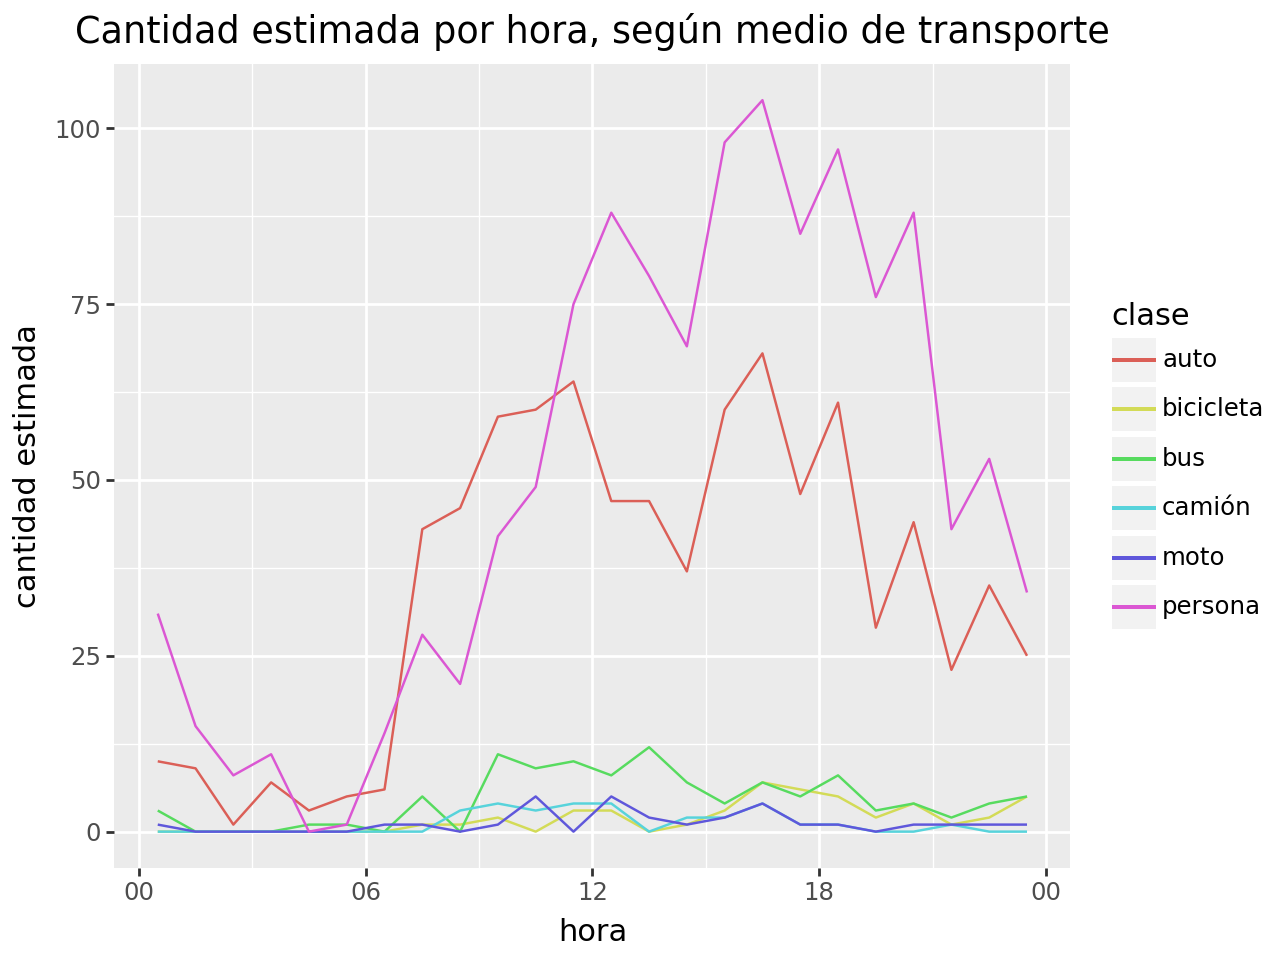

In [61]:
fig.show()

Gráfico de variación de la cantidad estimada de personas, por hora, según medio de transporte

In [62]:
audiencia_larga = audiencia_estimada.melt(
    id_vars=["hora"],
    var_name="clase",
    value_name="audiencia_estimada"
)
# audiencia_larga

In [63]:
fig = (
    ggplot(audiencia_larga, aes(x="hora", y="audiencia_estimada", colour="clase", group="clase"))
    + geom_line(size=.5)
    + scale_x_date(date_labels="%H")
    + labs(
        y="audiencia estimada",
        x="hora",
        title="Audiencia estimada por hora, según medio de transporte"
    )
)

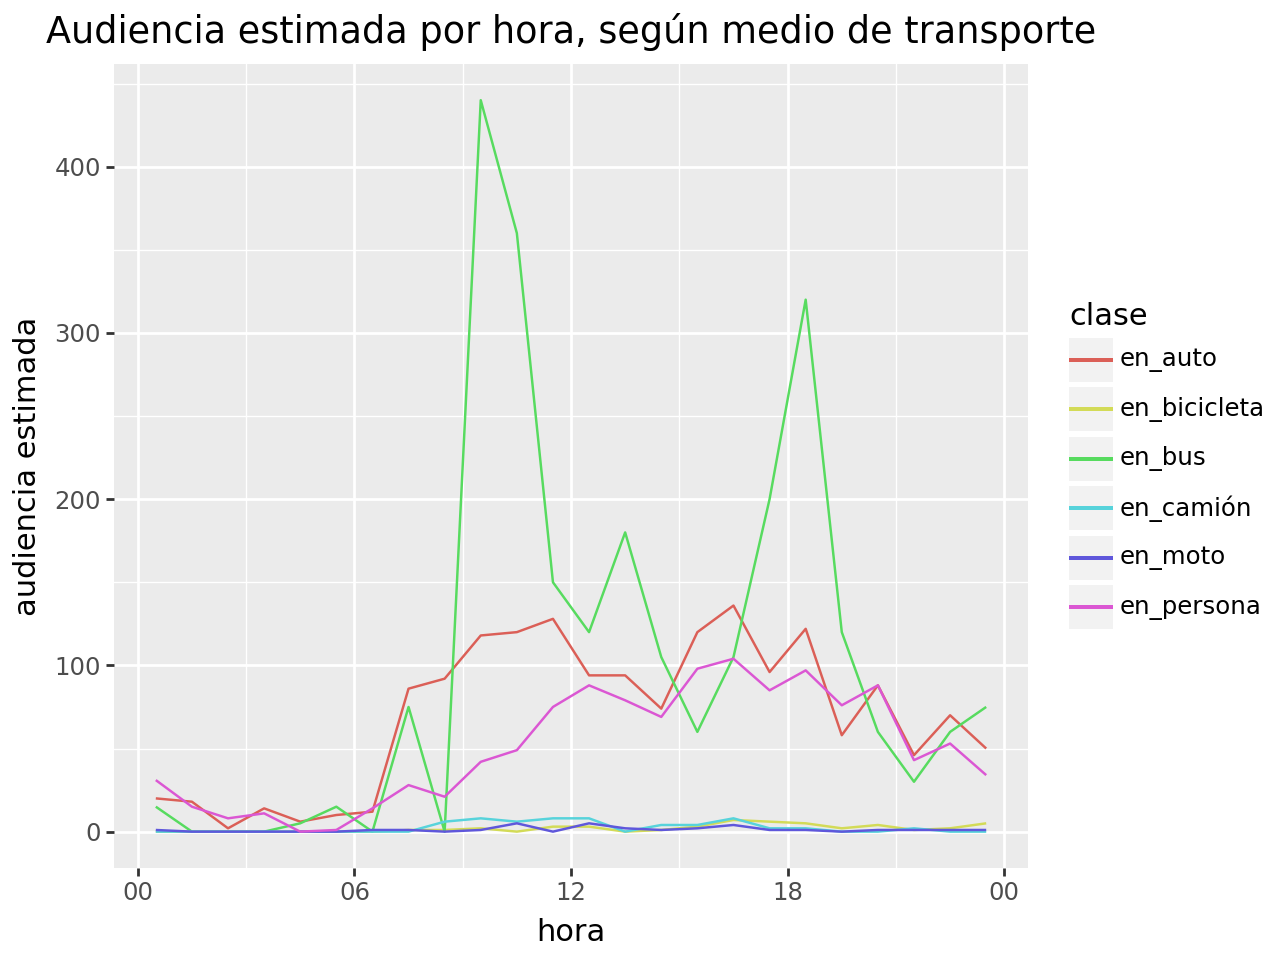

In [64]:
fig.show()